# How has music changed over time, and what predicts popularity?
**Dataset:** TidyTuesday Spotify songs (Jan 2020) — ~33k tracks pulled from Spotify playlists, with audio features, a popularity score and release date.

**Question 1:** How have the audio features of tracks changed from the 1960s to the 2010s?
**Question 2:** How well do audio features alone predict a track's popularity?

## 1. Setup and load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
try:
    df = pd.read_csv("spotify_songs.csv")          # local copy if you have one
except FileNotFoundError:
    df = pd.read_csv(URL)
    df.to_csv("spotify_songs.csv", index=False)    # save a copy so it works offline

df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


## 2. Inspect the raw data

In [2]:
print(df.shape)
df.info()

(32833, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  

In [3]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Duplicate track_ids:", df.track_id.duplicated().sum())
print("Duplicate name+artist:", df.duplicated(["track_name", "track_artist"]).sum())
print("Popularity = 0:", (df.track_popularity == 0).sum())
print("Release-date string lengths:\n", df.track_album_release_date.str.len().value_counts())

Missing values:
 track_name          5
track_artist        5
track_album_name    5
dtype: int64 

Duplicate track_ids: 4477
Duplicate name+artist: 6603
Popularity = 0: 2703
Release-date string lengths:
 track_album_release_date
10    30947
4      1855
7        31
Name: count, dtype: int64


**Data Findings**

• 5 rows had no track name, artist or album name, so I removed them.

• 6,599 further rows were duplicates (the same song in several playlists). I removed them, leaving 26,229 unique songs.

• Release dates came in 3 formats (full date, year-month and year only), so I parsed them with format="mixed".

• 8.6% of songs have a popularity of 0. I kept them, as they aren't clearly errors.


## 3. Clean

In [4]:
clean = df.copy()

# 1. drop rows with no track name / artist
clean = clean.dropna(subset=["track_name", "track_artist"])

# 2. one row per song: keep the most popular copy of each (name + artist)
clean = (clean.sort_values(["track_popularity", "track_id"], ascending=[False, True]) # track_id breaks ties so results are reproducible
              .drop_duplicates(["track_name", "track_artist"]))

# 3. parse mixed-format dates and derive year / decade
clean["release_date"] = pd.to_datetime(clean.track_album_release_date, format="mixed")
clean["year"] = clean.release_date.dt.year
clean["decade"] = (clean.year // 10) * 10

print(f"{len(df):,} rows -> {len(clean):,} unique songs")
clean.groupby("decade").size()

32,833 rows -> 26,229 unique songs


decade
1950        3
1960      117
1970      692
1980      970
1990     1830
2000     3273
2010    18722
2020      622
dtype: int64

In [5]:
print("Popularity = 0 after cleaning:", (clean.track_popularity == 0).sum(),
      f"({(clean.track_popularity == 0).mean():.1%})")

Popularity = 0 after cleaning: 2264 (8.6%)


Only 3 tracks are from the 1950s, which is too few to draw conclusions from, so I'll analyse **1960s–2010s** and leave out 1950s and 2020 (the data stops in January 2020).

In [6]:
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]

trend = clean[clean.decade.between(1960, 2010)]
by_decade = trend.groupby("decade")[FEATURES + ["track_popularity"]].mean()
by_decade["n_tracks"] = trend.groupby("decade").size()
by_decade.round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,track_popularity,n_tracks
decade,,,,,,,,,,,,
1960,0.50,0.59,-9.93,0.05,0.34,0.09,0.19,0.61,122.53,215834.30,50.52,117
1970,0.54,0.63,-9.79,0.05,0.25,0.06,0.19,0.61,122.66,257089.94,46.79,692
1980,0.61,0.69,-9.55,0.06,0.16,0.05,0.18,0.63,121.65,266457.94,44.35,970
1990,0.67,0.66,-8.57,0.12,0.15,0.04,0.20,0.60,115.77,264424.37,40.50,1830
2000,0.64,0.71,-6.68,0.11,0.17,0.05,0.20,0.60,119.29,246544.33,33.71,3273
2010,0.66,0.70,-6.43,0.11,0.18,0.11,0.19,0.47,121.67,215847.25,41.05,18722


## 4. Trends over time

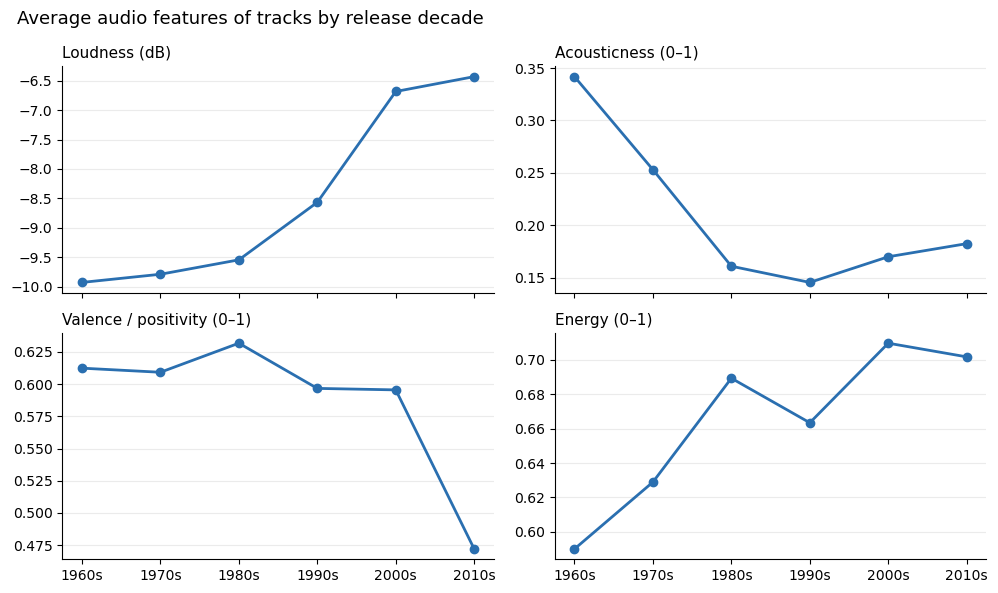

In [7]:
PANELS = [("loudness", "Loudness (dB)"), ("acousticness", "Acousticness (0–1)"),
          ("valence", "Valence / positivity (0–1)"), ("energy", "Energy (0–1)")]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, (col, label) in zip(axes.flat, PANELS):
    ax.plot(by_decade.index, by_decade[col], color="#2a6fb0", linewidth=2, marker="o", markersize=6)
    ax.set_title(label, loc="left", fontsize=11)
    ax.grid(axis="y", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xticks(by_decade.index)
    ax.set_xticklabels([f"{d}s" for d in by_decade.index])
fig.suptitle("Average audio features of tracks by release decade", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.savefig("trends_by_decade.png", dpi=150)
plt.show()

In [8]:
print("Loudness-energy correlation:", round(clean.loudness.corr(clean.energy), 2))

Loudness-energy correlation: 0.69


**Interpreting the trends**

The biggest change is loudness, which rose in every decade, from -9.93 dB in the 1960s to -6.43 dB in the 2010s, an increase of 3.5 dB. Valence (how positive a track sounds) stayed steady at around 0.6 until the 2000s, then fell sharply to 0.47 in the 2010s. Loudness and energy also moved together: energy rose from 0.59 to about 0.70 over the same period, and the two features are strongly correlated (r = 0.69). However, the 1960s have only 117 tracks compared with 18,722 in the 2010s, so the earlier decades are less reliable.

## 5. Which features relate to popularity?

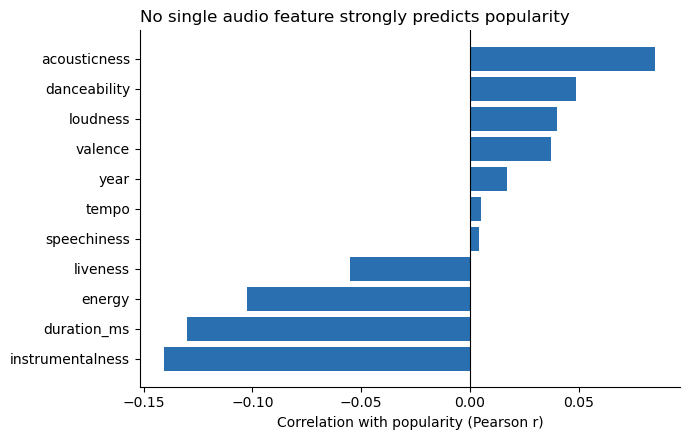

In [9]:
corr = (clean[FEATURES + ["year", "track_popularity"]]
        .corr()["track_popularity"]
        .drop("track_popularity")
        .sort_values())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(corr.index, corr.values, color="#2a6fb0")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with popularity (Pearson r)")
ax.set_title("No single audio feature strongly predicts popularity", loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.savefig("correlations.png", dpi=150)
plt.show()

**Interpreting the correlations**

The chart shows that no audio feature is strongly related to popularity. The strongest correlation is instrumentalness at -0.14, meaning more instrumental tracks tend to be slightly less popular. Duration (-0.13) and energy (-0.10) are also weakly negative, while acousticness (+0.09) is the highest positive. Danceability (+0.05), loudness (+0.04) and valence (+0.04) are close to zero, and speechiness and tempo show essentially no relationship. Correlation only captures straight-line relationships, so non-linear effects are possible (see section 6). However, with every correlation at about 0.14 or below and the best model explaining only 15.7% of the variation, much of what drives popularity probably lies outside this data, such as artist fame and playlist placement.

Year is also barely correlated with popularity (+0.02), even though average popularity differs by decade: it falls from 50.5 in the 1960s to 33.7 in the 2000s, then rises to 41.1 in the 2010s. This is probably because the pattern isn’t a straight line, and because the 2010s make up 18,722 of the 26,229 songs and dominate the result. Popularity is also a current score, so older songs still on playlists today may be well-known classics rather than typical releases.

## 6. Can audio features predict popularity?

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

X = clean[FEATURES + ["year"]]
y = clean["track_popularity"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# baseline: always predict the average popularity
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           random_state=42, n_jobs=-1),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({"model": name, "R2": r2_score(y_test, pred),
                 "MAE": mean_absolute_error(y_test, pred)})
rows.append({"model": "Predict-the-average baseline", "R2": 0.0, "MAE": baseline_mae})
results = pd.DataFrame(rows).round(3)
results

,model,R2,MAE
0,Linear regression,0.063,18.597
1,Random forest,0.157,17.437
2,Predict-the-average baseline,0.000,19.252


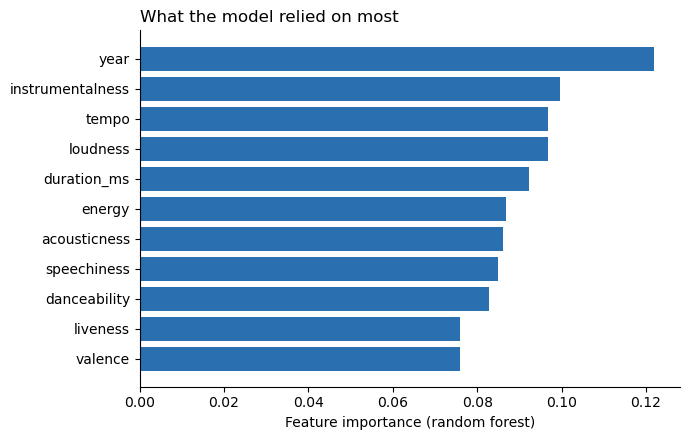

year                0.122
instrumentalness    0.100
tempo               0.097
loudness            0.097
duration_ms         0.092
dtype: float64


In [11]:
rf = models["Random forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color="#2a6fb0")
ax.set_xlabel("Feature importance (random forest)")
ax.set_title("What the model relied on most", loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).round(3).head(5))


**Interpreting the model results**

I trained a linear regression and a random forest to predict popularity from the ten audio features plus release year, and tested both on a held-out 20% of songs. The random forest performed best with an R² of 0.157, meaning the features explain about 15.7% of the variation in popularity. Its average error (MAE) was 17.4 points, only about 2 points better than the 19.3 from always predicting the average. The linear regression was weaker, with an R² of 0.063 and an MAE of 18.6. The forest’s advantage suggests some relationships between features and popularity are not straight lines.

Feature importances were spread fairly evenly, with year (0.122), instrumentalness (0.100), tempo (0.097), loudness (0.097) and duration (0.092) at the top, and no single feature dominating. Tempo and loudness ranked highly even though their correlations with popularity were close to zero, which may also point to non-linear effects. Importance doesn’t show whether a feature raises or lowers popularity, so this ranking shouldn’t be over-interpreted.


## 7. Conclusions

How has music changed? 

Among the 26,229 unique tracks analysed (1960s to 2010s), music became louder, more energetic and less acoustic. Average loudness rose by 3.5 dB, from -9.93 dB in the 1960s to -6.43 dB in the 2010s, and energy rose from 0.59 to about 0.70. Acousticness halved between the 1960s and the 1980s (0.34 to 0.16), and valence, a measure of how positive a track sounds, held at around 0.6 until the 2000s before dropping to 0.47 in the 2010s.

Can audio features predict popularity? 

Only weakly. No single feature had a correlation with popularity stronger than ±0.14, and the best model, a random forest, explained about 15.7% of the variation in popularity (R² = 0.157) with an average error of 17.4 points, only about 2 points better than always predicting the average. Audio features alone are not enough to tell what makes a track popular.

Limitations:

- Tracks come from Spotify playlists, not a random sample of all music, and the 2010s are heavily over-represented (18,722 of 26,229 tracks) compared with the 1960s (117).
- Popularity is a current score, so older songs are not comparable with newer ones.
- Factors such as artist fame, marketing and playlist placement are not in the data, and probably explain much of the remaining variation.
- The data ends in January 2020.

Could improve:

- Add artist-level information: Features such as an artist’s follower count or previous hits would test whether who made a track matters more than how it sounds. This is the most direct way to address the biggest limitation.
- Account for release date when measuring popularity: Because popularity is a current score, I could compare tracks only with others from the same year, or use a ranking within each year, so older and newer songs are measured fairly.
- Improve the model: I could tune the random forest, try gradient boosting, and use cross-validation for a more reliable estimate than a single train/test split.